## Movement Along One Delivery Route (Flag 12)

### Dataset Overview

A continuous one-day courier trajectory through four service clusters, linked to 20 accepted delivery tasks and their completion sequence. Road reconstruction: 725 GPS points along the archived local OSM street network, with all road vertices retained and irregular moving intervals bounded by 45 m. Oneway tags are respected; turn-restriction relations are not modeled. Times are local Shanghai time; speed_kmh and activity_state describe the preceding segment. Task events and AOI locations are constructed, not authentic observations. Tasks are released in batches as the courier approaches successive service clusters. Priority comparisons cover the complete route and all currently accepted tasks; each task pair is counted at its first qualifying instant, regardless of its eventual completion order.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze movement and delivery activity along the observed courier route.

Role: Last-mile delivery operations analyst


Category: route orientation, spatial task ordering, and cluster movement


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What is the overall direction and reversal pattern of the courier's route?

#### Analysis action

Follow GPS points in time order and inspect signed progression around the route center and large consecutive course changes.

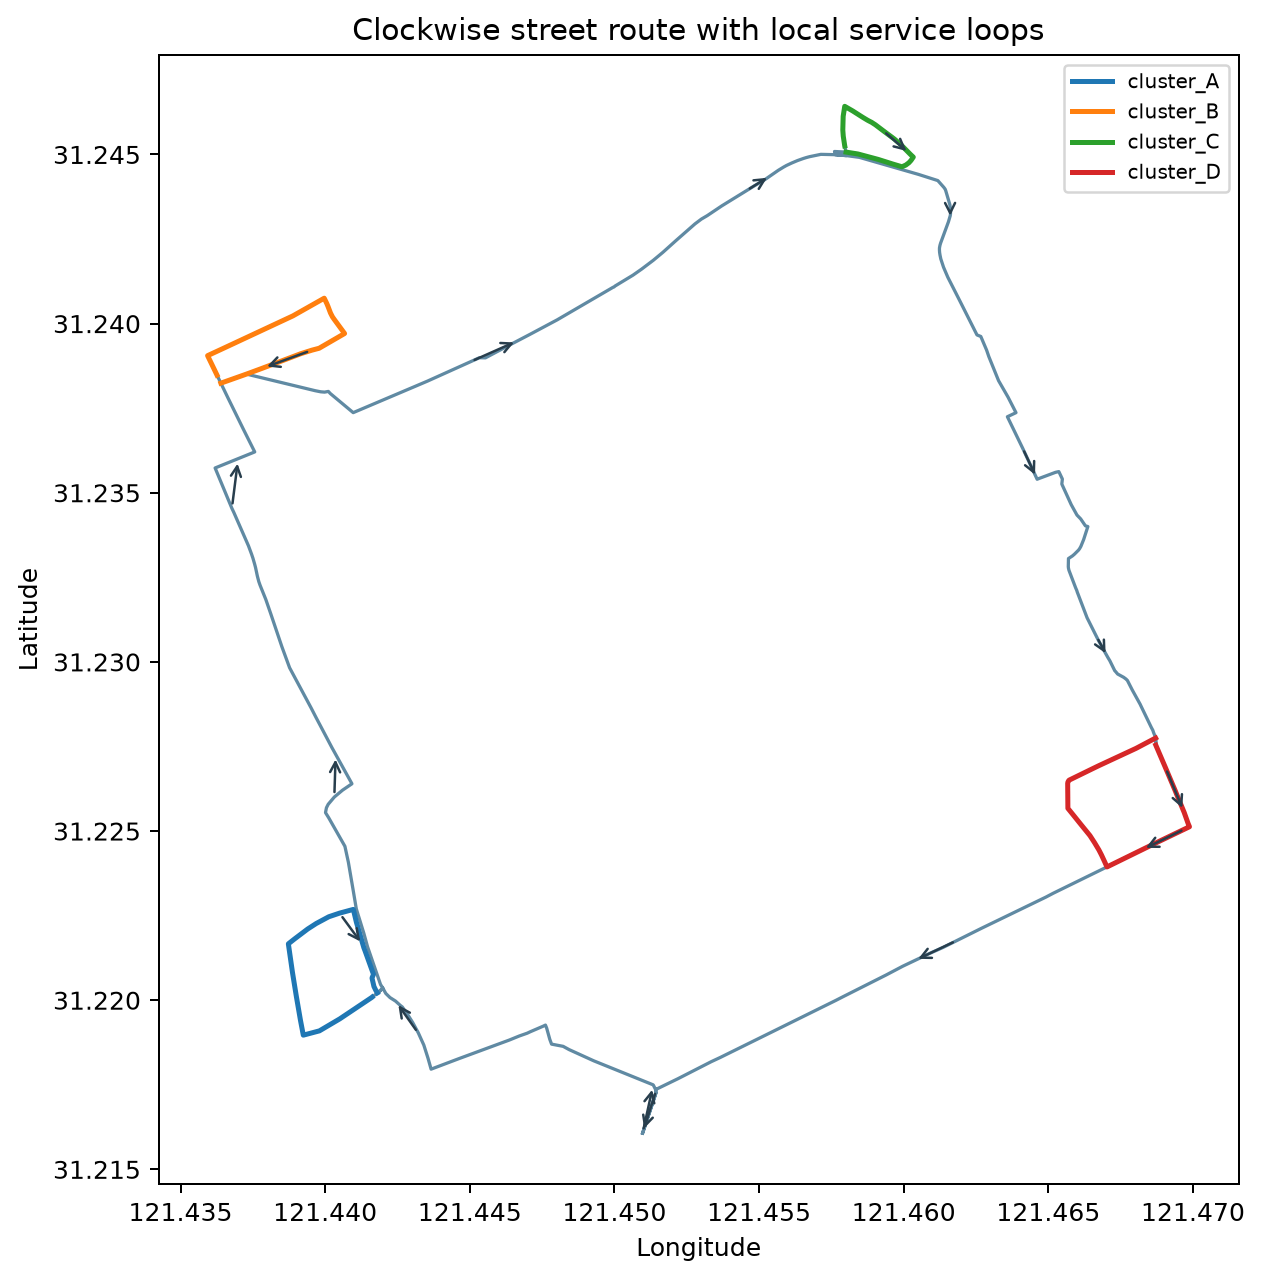

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def route_orientation(df, user_df):
    q = user_df.sort_values("point_index")
    xy = q[["lng", "lat"]].to_numpy() * [95.2, 111]
    shifted = xy - xy.mean(axis=0)
    area = float(
        0.5
        * np.sum(shifted[:-1, 0] * shifted[1:, 1] - shifted[1:, 0] * shifted[:-1, 1])
    )
    fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
    ax.plot(q.lng, q.lat, color="#608aa3", lw=1.3)
    for name, s in q[q.route_phase.eq("cluster_service")].groupby("route_section"):
        ax.plot(s.lng, s.lat, lw=2, label=name)
    for i in np.linspace(0, len(q) - 8, 16, dtype=int):
        ax.annotate(
            "",
            xy=(q.iloc[i + 7].lng, q.iloc[i + 7].lat),
            xytext=(q.iloc[i].lng, q.iloc[i].lat),
            arrowprops={"arrowstyle": "->", "color": "#283e4d"},
        )
    ax.set(
        xlabel="Longitude",
        ylabel="Latitude",
        title="Clockwise street route with local service loops",
    )
    ax.set_aspect(1 / np.cos(np.radians(q.lat.mean())))
    ax.ticklabel_format(useOffset=False)
    ax.legend(fontsize=8)
    return {
        "signed_area_km2": area,
        "route_orientation": "clockwise" if area < 0 else "counterclockwise",
        "immediate_reversal_count": int(q.directional_change_deg.ge(135).sum()),
    }


evidence = route_orientation(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/clockwise_route_map.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "ordered_route_geometry",
  "insight_type": "overall_pattern",
  "insight": "The courier follows a mostly clockwise route, with few immediate reversals.",
  "insight_value": {
    "signed_area_km2": -6.410675269420116,
    "route_orientation": "clockwise",
    "immediate_reversal_count": 1
  },
  "plot": {
    "plot_type": "directed_route_map",
    "title": "Clockwise Delivery Route",
    "file": "visualizations/clockwise_route_map.png",
    "description": "Recomputed from the delivered CSVs; road geometry preserves mapped vertices."
  },
  "question": "What is the overall direction and reversal pattern of the courier's route?",
  "actionable_insight": "Follow GPS points in time order and inspect signed progression around the route center and large consecutive course changes.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef route_orientation(df,user_df):\n    q=user_df.sort_values('point_index');xy=q[['lng','lat']].to_numpy()*[95.2,111]\n    shifted=xy-xy.mean(axis=0)\n    area=float(.5*np.sum(shifted[:-1,0]*shifted[1:,1]-shifted[1:,0]*shifted[:-1,1]))\n    fig,ax=plt.subplots(figsize=(9,7),constrained_layout=True)\n    ax.plot(q.lng,q.lat,color='#608aa3',lw=1.3)\n    for name,s in q[q.route_phase.eq('cluster_service')].groupby('route_section'):\n        ax.plot(s.lng,s.lat,lw=2,label=name)\n    for i in np.linspace(0,len(q)-8,16,dtype=int):\n        ax.annotate('',xy=(q.iloc[i+7].lng,q.iloc[i+7].lat),xytext=(q.iloc[i].lng,q.iloc[i].lat),arrowprops={'arrowstyle':'->','color':'#283e4d'})\n    ax.set(xlabel='Longitude',ylabel='Latitude',title='Clockwise street route with local service loops')\n    ax.set_aspect(1/np.cos(np.radians(q.lat.mean())));ax.ticklabel_format(useOffset=False);ax.legend(fontsize=8)\n    return {'signed_area_km2':area,'route_orientation':'clockwise' if area<0 else 'counterclockwise','immediate_reversal_count':int(q.directional_change_deg.ge(135).sum())}\n\nevidence=route_orientation(df,user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_time",
    "gps_position"
  ]
}

### **Question 2**: When an accepted delivery lies just behind the courier, are farther tasks ahead sometimes completed first?

#### Analysis action

Compare accepted task locations and completion times with the time-ordered route through each cluster.

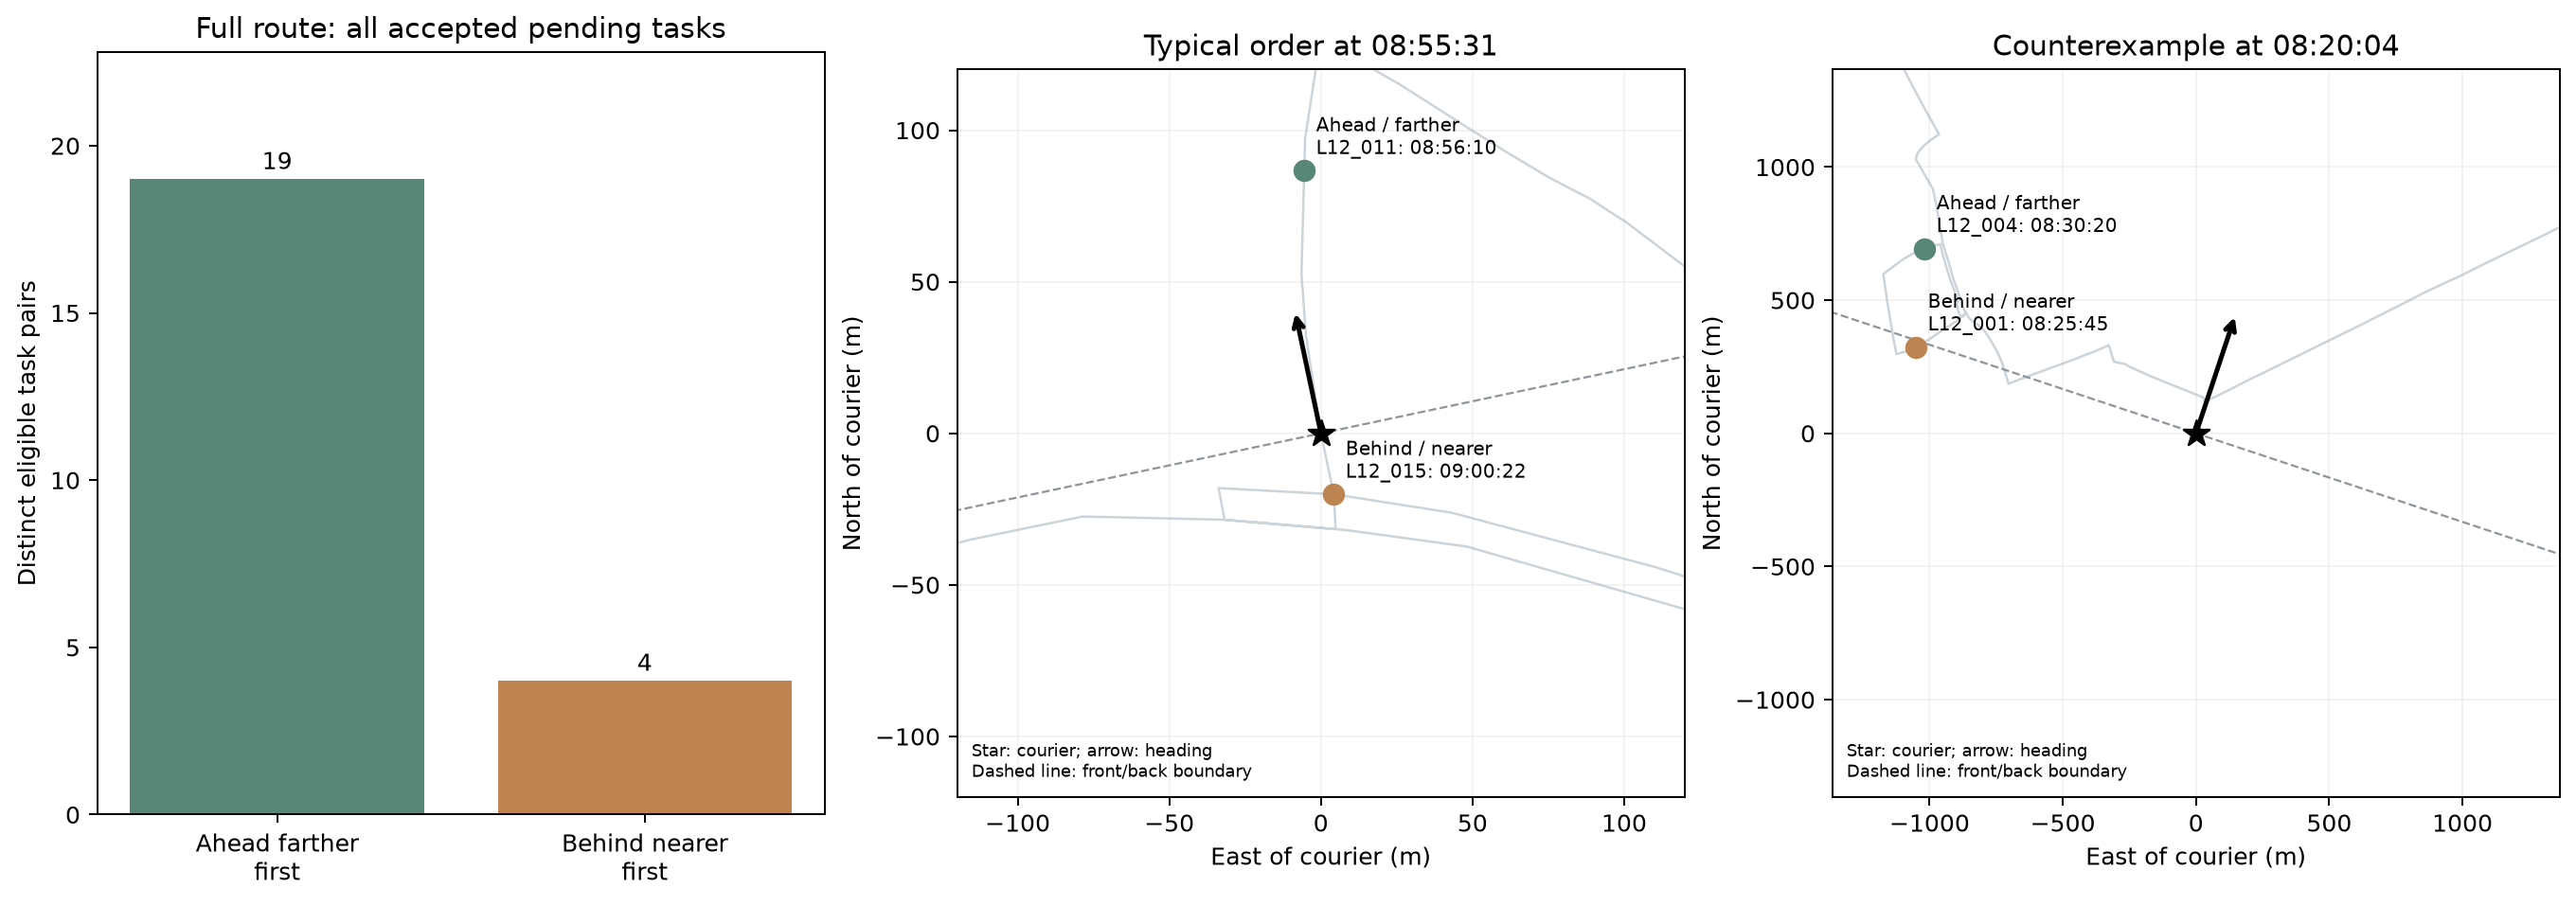

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def ahead_before_behind(df, user_df):
    tasks = df.reset_index(drop=True)
    q = user_df.sort_values("point_index").reset_index(drop=True)
    xy = q[["lng", "lat"]].to_numpy() * [95.2, 111]
    dest = tasks[["task_lng", "task_lat"]].to_numpy() * [95.2, 111]
    starts = (
        pd.to_datetime(tasks.accept_time, format="mixed").astype("int64").to_numpy()
    )
    ends = (
        pd.to_datetime(tasks.completion_time, format="mixed").astype("int64").to_numpy()
    )
    times = pd.to_datetime(q.gps_time, format="mixed").astype("int64").to_numpy()
    found = {}
    for i in range(len(q) - 1):
        heading = xy[i + 1] - xy[i]
        if np.linalg.norm(heading) < 1e-9:
            continue
        vectors = dest - xy[i]
        dots = vectors @ heading
        distance = np.linalg.norm(vectors, axis=1)
        pending = (starts <= times[i]) & (ends > times[i])
        eligible = (
            (pending & (dots > 0))[:, None]
            & (pending & (dots < 0))[None, :]
            & (distance[:, None] > distance[None, :])
        )
        for a, b in zip(*np.where(eligible)):
            key = tuple(sorted((int(a), int(b))))
            if key in found:
                continue
            found[key] = {
                "cluster": str(tasks.service_cluster.iloc[a]),
                "ahead_task_id": str(tasks.task_id.iloc[a]),
                "behind_task_id": str(tasks.task_id.iloc[b]),
                "comparison_time": str(q.gps_time.iloc[i]),
                "point_index": int(q.point_index.iloc[i]),
                "ahead_distance_km": float(distance[a]),
                "behind_distance_km": float(distance[b]),
                "ahead_completion_time": str(tasks.completion_time.iloc[a]),
                "behind_completion_time": str(tasks.completion_time.iloc[b]),
                "outcome": (
                    "Ahead farther first"
                    if ends[a] < ends[b]
                    else "Behind nearer first"
                ),
            }
    pairs = list(found.values())
    positive = [r for r in pairs if r["outcome"] == "Ahead farther first"]
    reverse = [r for r in pairs if r["outcome"] == "Behind nearer first"]
    assert positive and reverse
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), constrained_layout=True)
    counts = [len(positive), len(reverse)]
    axes[0].bar(
        ["Ahead farther\nfirst", "Behind nearer\nfirst"],
        counts,
        color=["#588677", "#bd8452"],
    )
    for i, n in enumerate(counts):
        axes[0].text(i, n + 0.3, str(n), ha="center")
    axes[0].set(
        ylim=(0, max(counts) * 1.2),
        ylabel="Distinct eligible task pairs",
        title="Full route: all accepted pending tasks",
    )
    for ax, options, label in zip(
        axes[1:], [positive, reverse], ["Typical order", "Counterexample"]
    ):
        pair = min(
            options, key=lambda r: r["ahead_distance_km"] + r["behind_distance_km"]
        )
        i = pair["point_index"]
        origin = xy[i]
        heading = xy[i + 1] - origin
        indices = [
            tasks.index[tasks.task_id.eq(pair[k])][0]
            for k in ["ahead_task_id", "behind_task_id"]
        ]
        locations = (dest[indices] - origin) * 1000
        line = (xy - origin) * 1000
        span = max(120, float(np.max(np.abs(locations))) * 1.3)
        ax.plot(line[:, 0], line[:, 1], color="#ccd4d9", lw=1, zorder=0)
        ax.scatter(
            [0], [0], marker="*", s=130, color="black", label="Courier", zorder=4
        )
        arrow = heading / np.linalg.norm(heading) * span * 0.35
        ax.annotate(
            "",
            xy=arrow,
            xytext=(0, 0),
            arrowprops={"arrowstyle": "->", "color": "black", "lw": 2},
        )
        perpendicular = (
            np.array([-heading[1], heading[0]]) / np.linalg.norm(heading) * span * 2
        )
        ax.plot(
            [-perpendicular[0], perpendicular[0]],
            [-perpendicular[1], perpendicular[1]],
            "--",
            color="#8e969b",
            lw=0.9,
        )
        ax.text(
            0.02,
            0.02,
            "Star: courier; arrow: heading\nDashed line: front/back boundary",
            transform=ax.transAxes,
            fontsize=7,
            va="bottom",
        )
        for j, (pos, index) in enumerate(zip(locations, indices)):
            name = "Ahead / farther" if j == 0 else "Behind / nearer"
            ax.scatter(*pos, s=70, color=["#588677", "#bd8452"][j], zorder=3)
            text = f"{name}\n{tasks.task_id.iloc[index]}: " + pd.Timestamp(
                tasks.completion_time.iloc[index]
            ).strftime("%H:%M:%S")
            ax.annotate(
                text, pos, xytext=(5, 7), textcoords="offset points", fontsize=8
            )
        ax.set(
            xlim=(-span, span),
            ylim=(-span, span),
            aspect="equal",
            xlabel="East of courier (m)",
            ylabel="North of courier (m)",
            title=label
            + " at "
            + pd.Timestamp(pair["comparison_time"]).strftime("%H:%M:%S"),
        )
        ax.grid(alpha=0.15)
    return {
        "verified_pairs": len(positive),
        "eligible_pairs": len(pairs),
        "counterexample_pairs": len(reverse),
        "ahead_farther_completed_first_share": len(positive) / len(pairs),
        "clusters_with_pattern": len({x["cluster"] for x in positive}),
        "pair_evidence": pairs,
        "comparison_rule": (
            "Whole route, all accepted and uncompleted tasks; each unordered task pair"
            " counted once at its first qualifying GPS instant. Heading uses the next"
            " moving GPS segment. No cluster or completion-order preselection."
        ),
    }


evidence = ahead_before_behind(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/ahead_before_behind_tasks.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "pending_task_spatial_completion_order",
  "insight_type": "factor_relationship",
  "insight": "Farther deliveries ahead are often completed before nearer deliveries located behind the courier.",
  "insight_value": {
    "verified_pairs": 19,
    "eligible_pairs": 23,
    "counterexample_pairs": 4,
    "ahead_farther_completed_first_share": 0.8260869565217391,
    "clusters_with_pattern": 4,
    "pair_evidence": [
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_003",
        "behind_task_id": "L12_001",
        "comparison_time": "2026-07-08 08:20:04.746365907",
        "point_index": 1,
        "ahead_distance_km": 1.2991883713368073,
        "behind_distance_km": 1.099533251400523,
        "ahead_completion_time": "2026-07-08 08:28:42.181853569",
        "behind_completion_time": "2026-07-08 08:25:45.337785534",
        "outcome": "Behind nearer first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_003",
        "behind_task_id": "L12_002",
        "comparison_time": "2026-07-08 08:20:04.746365907",
        "point_index": 1,
        "ahead_distance_km": 1.2991883713368073,
        "behind_distance_km": 1.20039127057767,
        "ahead_completion_time": "2026-07-08 08:28:42.181853569",
        "behind_completion_time": "2026-07-08 08:27:12.200835622",
        "outcome": "Behind nearer first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_004",
        "behind_task_id": "L12_001",
        "comparison_time": "2026-07-08 08:20:04.746365907",
        "point_index": 1,
        "ahead_distance_km": 1.2322080663868806,
        "behind_distance_km": 1.099533251400523,
        "ahead_completion_time": "2026-07-08 08:30:20.795411422",
        "behind_completion_time": "2026-07-08 08:25:45.337785534",
        "outcome": "Behind nearer first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_004",
        "behind_task_id": "L12_002",
        "comparison_time": "2026-07-08 08:20:04.746365907",
        "point_index": 1,
        "ahead_distance_km": 1.2322080663868806,
        "behind_distance_km": 1.20039127057767,
        "ahead_completion_time": "2026-07-08 08:30:20.795411422",
        "behind_completion_time": "2026-07-08 08:27:12.200835622",
        "outcome": "Behind nearer first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_003",
        "behind_task_id": "L12_004",
        "comparison_time": "2026-07-08 08:23:40.113588249",
        "point_index": 57,
        "ahead_distance_km": 0.3267769047574986,
        "behind_distance_km": 0.2870400175620327,
        "ahead_completion_time": "2026-07-08 08:28:42.181853569",
        "behind_completion_time": "2026-07-08 08:30:20.795411422",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_001",
        "behind_task_id": "L12_005",
        "comparison_time": "2026-07-08 08:23:56.692321826",
        "point_index": 60,
        "ahead_distance_km": 0.18183436592512625,
        "behind_distance_km": 0.02185978010719797,
        "ahead_completion_time": "2026-07-08 08:25:45.337785534",
        "behind_completion_time": "2026-07-08 08:33:37.591138235",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_002",
        "behind_task_id": "L12_005",
        "comparison_time": "2026-07-08 08:23:56.692321826",
        "point_index": 60,
        "ahead_distance_km": 0.2455276450056832,
        "behind_distance_km": 0.02185978010719797,
        "ahead_completion_time": "2026-07-08 08:27:12.200835622",
        "behind_completion_time": "2026-07-08 08:33:37.591138235",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_003",
        "behind_task_id": "L12_005",
        "comparison_time": "2026-07-08 08:23:56.692321826",
        "point_index": 60,
        "ahead_distance_km": 0.30705638634389326,
        "behind_distance_km": 0.02185978010719797,
        "ahead_completion_time": "2026-07-08 08:28:42.181853569",
        "behind_completion_time": "2026-07-08 08:33:37.591138235",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_A",
        "ahead_task_id": "L12_004",
        "behind_task_id": "L12_005",
        "comparison_time": "2026-07-08 08:27:22.448232037",
        "point_index": 76,
        "ahead_distance_km": 0.3207443779799988,
        "behind_distance_km": 0.2647104037579451,
        "ahead_completion_time": "2026-07-08 08:30:20.795411422",
        "behind_completion_time": "2026-07-08 08:33:37.591138235",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_B",
        "ahead_task_id": "L12_008",
        "behind_task_id": "L12_009",
        "comparison_time": "2026-07-08 08:39:55.997185712",
        "point_index": 210,
        "ahead_distance_km": 0.441023364272238,
        "behind_distance_km": 0.3411750724436783,
        "ahead_completion_time": "2026-07-08 08:44:12.091466925",
        "behind_completion_time": "2026-07-08 08:46:09.319897647",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_B",
        "ahead_task_id": "L12_006",
        "behind_task_id": "L12_010",
        "comparison_time": "2026-07-08 08:40:12.499455459",
        "point_index": 212,
        "ahead_distance_km": 0.12071066649157802,
        "behind_distance_km": 0.028956503896408598,
        "ahead_completion_time": "2026-07-08 08:41:24.235355984",
        "behind_completion_time": "2026-07-08 08:48:53.245106650",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_B",
        "ahead_task_id": "L12_007",
        "behind_task_id": "L12_010",
        "comparison_time": "2026-07-08 08:40:12.499455459",
        "point_index": 212,
        "ahead_distance_km": 0.2847540843814096,
        "behind_distance_km": 0.028956503896408598,
        "ahead_completion_time": "2026-07-08 08:42:45.697361809",
        "behind_completion_time": "2026-07-08 08:48:53.245106650",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_B",
        "ahead_task_id": "L12_008",
        "behind_task_id": "L12_010",
        "comparison_time": "2026-07-08 08:40:12.499455459",
        "point_index": 212,
        "ahead_distance_km": 0.4310620626646363,
        "behind_distance_km": 0.028956503896408598,
        "ahead_completion_time": "2026-07-08 08:44:12.091466925",
        "behind_completion_time": "2026-07-08 08:48:53.245106650",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_B",
        "ahead_task_id": "L12_009",
        "behind_task_id": "L12_010",
        "comparison_time": "2026-07-08 08:40:55.438183126",
        "point_index": 216,
        "ahead_distance_km": 0.33848587134567637,
        "behind_distance_km": 0.10458620608302802,
        "ahead_completion_time": "2026-07-08 08:46:09.319897647",
        "behind_completion_time": "2026-07-08 08:48:53.245106650",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_C",
        "ahead_task_id": "L12_011",
        "behind_task_id": "L12_015",
        "comparison_time": "2026-07-08 08:55:31.990468655",
        "point_index": 362,
        "ahead_distance_km": 0.08685088693678872,
        "behind_distance_km": 0.020553212999429363,
        "ahead_completion_time": "2026-07-08 08:56:10.564243577",
        "behind_completion_time": "2026-07-08 09:00:22.800047864",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_C",
        "ahead_task_id": "L12_012",
        "behind_task_id": "L12_015",
        "comparison_time": "2026-07-08 08:55:31.990468655",
        "point_index": 362,
        "ahead_distance_km": 0.11115456600296662,
        "behind_distance_km": 0.020553212999429363,
        "ahead_completion_time": "2026-07-08 08:56:56.635232223",
        "behind_completion_time": "2026-07-08 09:00:22.800047864",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_C",
        "ahead_task_id": "L12_013",
        "behind_task_id": "L12_015",
        "comparison_time": "2026-07-08 08:55:32.276827656",
        "point_index": 363,
        "ahead_distance_km": 0.15846796141277059,
        "behind_distance_km": 0.021159619440621173,
        "ahead_completion_time": "2026-07-08 08:57:41.259459085",
        "behind_completion_time": "2026-07-08 09:00:22.800047864",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_C",
        "ahead_task_id": "L12_014",
        "behind_task_id": "L12_015",
        "comparison_time": "2026-07-08 08:57:02.725779598",
        "point_index": 376,
        "ahead_distance_km": 0.19374084199842048,
        "behind_distance_km": 0.12630207244253192,
        "ahead_completion_time": "2026-07-08 08:58:39.257958838",
        "behind_completion_time": "2026-07-08 09:00:22.800047864",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_D",
        "ahead_task_id": "L12_016",
        "behind_task_id": "L12_020",
        "comparison_time": "2026-07-08 09:07:36.727060987",
        "point_index": 557,
        "ahead_distance_km": 0.17993014714400232,
        "behind_distance_km": 0.023304570785204544,
        "ahead_completion_time": "2026-07-08 09:08:57.881822609",
        "behind_completion_time": "2026-07-08 09:16:09.960936332",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_D",
        "ahead_task_id": "L12_017",
        "behind_task_id": "L12_020",
        "comparison_time": "2026-07-08 09:07:36.727060987",
        "point_index": 557,
        "ahead_distance_km": 0.3149453399294562,
        "behind_distance_km": 0.023304570785204544,
        "ahead_completion_time": "2026-07-08 09:10:19.555103911",
        "behind_completion_time": "2026-07-08 09:16:09.960936332",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_D",
        "ahead_task_id": "L12_018",
        "behind_task_id": "L12_020",
        "comparison_time": "2026-07-08 09:07:36.727060987",
        "point_index": 557,
        "ahead_distance_km": 0.41741152687671157,
        "behind_distance_km": 0.023304570785204544,
        "ahead_completion_time": "2026-07-08 09:11:38.575806572",
        "behind_completion_time": "2026-07-08 09:16:09.960936332",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_D",
        "ahead_task_id": "L12_019",
        "behind_task_id": "L12_020",
        "comparison_time": "2026-07-08 09:07:36.727060987",
        "point_index": 557,
        "ahead_distance_km": 0.3368674057740232,
        "behind_distance_km": 0.023304570785204544,
        "ahead_completion_time": "2026-07-08 09:13:31.009426105",
        "behind_completion_time": "2026-07-08 09:16:09.960936332",
        "outcome": "Ahead farther first"
      },
      {
        "cluster": "cluster_D",
        "ahead_task_id": "L12_018",
        "behind_task_id": "L12_019",
        "comparison_time": "2026-07-08 09:08:03.499835319",
        "point_index": 559,
        "ahead_distance_km": 0.38106977252568186,
        "behind_distance_km": 0.33430330697734356,
        "ahead_completion_time": "2026-07-08 09:11:38.575806572",
        "behind_completion_time": "2026-07-08 09:13:31.009426105",
        "outcome": "Ahead farther first"
      }
    ],
    "comparison_rule": "Whole route, all accepted and uncompleted tasks; each unordered task pair counted once at its first qualifying GPS instant. Heading uses the next moving GPS segment. No cluster or completion-order preselection."
  },
  "plot": {
    "plot_type": "small_multiples_route_and_task_order",
    "title": "Ahead-before-Behind Completion Pattern",
    "file": "visualizations/ahead_before_behind_tasks.png",
    "description": "Whole-route eligible-pair counts plus an annotated supporting comparison and counterexample, showing courier position, heading, task distances and completion times."
  },
  "question": "When an accepted delivery lies just behind the courier, are farther tasks ahead sometimes completed first?",
  "actionable_insight": "Compare accepted task locations and completion times with the time-ordered route through each cluster.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef ahead_before_behind(df,user_df):\n    tasks=df.reset_index(drop=True);q=user_df.sort_values('point_index').reset_index(drop=True)\n    xy=q[['lng','lat']].to_numpy()*[95.2,111]\n    dest=tasks[['task_lng','task_lat']].to_numpy()*[95.2,111]\n    starts=pd.to_datetime(tasks.accept_time,format='mixed').astype('int64').to_numpy()\n    ends=pd.to_datetime(tasks.completion_time,format='mixed').astype('int64').to_numpy()\n    times=pd.to_datetime(q.gps_time,format='mixed').astype('int64').to_numpy();found={}\n    for i in range(len(q)-1):\n        heading=xy[i+1]-xy[i]\n        if np.linalg.norm(heading)<1e-9:continue\n        vectors=dest-xy[i];dots=vectors@heading;distance=np.linalg.norm(vectors,axis=1)\n        pending=(starts<=times[i])&(ends>times[i])\n        eligible=(pending&(dots>0))[:,None]&(pending&(dots<0))[None,:]&(distance[:,None]>distance[None,:])\n        for a,b in zip(*np.where(eligible)):\n            key=tuple(sorted((int(a),int(b))))\n            if key in found:continue\n            found[key]={'cluster':str(tasks.service_cluster.iloc[a]),\n                'ahead_task_id':str(tasks.task_id.iloc[a]),'behind_task_id':str(tasks.task_id.iloc[b]),\n                'comparison_time':str(q.gps_time.iloc[i]),'point_index':int(q.point_index.iloc[i]),\n                'ahead_distance_km':float(distance[a]),'behind_distance_km':float(distance[b]),\n                'ahead_completion_time':str(tasks.completion_time.iloc[a]),'behind_completion_time':str(tasks.completion_time.iloc[b]),\n                'outcome':'Ahead farther first' if ends[a]<ends[b] else 'Behind nearer first'}\n    pairs=list(found.values());positive=[r for r in pairs if r['outcome']=='Ahead farther first']\n    reverse=[r for r in pairs if r['outcome']=='Behind nearer first']\n    assert positive and reverse\n    fig,axes=plt.subplots(1,3,figsize=(15,5.2),constrained_layout=True)\n    counts=[len(positive),len(reverse)];axes[0].bar(['Ahead farther\\nfirst','Behind nearer\\nfirst'],counts,color=['#588677','#bd8452'])\n    for i,n in enumerate(counts):axes[0].text(i,n+.3,str(n),ha='center')\n    axes[0].set(ylim=(0,max(counts)*1.2),ylabel='Distinct eligible task pairs',title='Full route: all accepted pending tasks')\n    for ax,options,label in zip(axes[1:],[positive,reverse],['Typical order','Counterexample']):\n        pair=min(options,key=lambda r:r['ahead_distance_km']+r['behind_distance_km'])\n        i=pair['point_index'];origin=xy[i];heading=xy[i+1]-origin\n        indices=[tasks.index[tasks.task_id.eq(pair[k])][0] for k in ['ahead_task_id','behind_task_id']]\n        locations=(dest[indices]-origin)*1000;line=(xy-origin)*1000\n        span=max(120,float(np.max(np.abs(locations)))*1.3)\n        ax.plot(line[:,0],line[:,1],color='#ccd4d9',lw=1,zorder=0)\n        ax.scatter([0],[0],marker='*',s=130,color='black',label='Courier',zorder=4)\n        arrow=heading/np.linalg.norm(heading)*span*.35\n        ax.annotate('',xy=arrow,xytext=(0,0),arrowprops={'arrowstyle':'->','color':'black','lw':2})\n        perpendicular=np.array([-heading[1],heading[0]])/np.linalg.norm(heading)*span*2\n        ax.plot([-perpendicular[0],perpendicular[0]],[-perpendicular[1],perpendicular[1]],\n            '--',color='#8e969b',lw=.9)\n        ax.text(.02,.02,'Star: courier; arrow: heading\\nDashed line: front/back boundary',\n            transform=ax.transAxes,fontsize=7,va='bottom')\n        for j,(pos,index) in enumerate(zip(locations,indices)):\n            name='Ahead / farther' if j==0 else 'Behind / nearer'\n            ax.scatter(*pos,s=70,color=['#588677','#bd8452'][j],zorder=3)\n            text=f'{name}\\n{tasks.task_id.iloc[index]}: '+pd.Timestamp(tasks.completion_time.iloc[index]).strftime('%H:%M:%S')\n            ax.annotate(text,pos,xytext=(5,7),textcoords='offset points',fontsize=8)\n        ax.set(xlim=(-span,span),ylim=(-span,span),aspect='equal',xlabel='East of courier (m)',ylabel='North of courier (m)',\n            title=label+' at '+pd.Timestamp(pair['comparison_time']).strftime('%H:%M:%S'))\n        ax.grid(alpha=.15)\n    return {'verified_pairs':len(positive),'eligible_pairs':len(pairs),'counterexample_pairs':len(reverse),\n        'ahead_farther_completed_first_share':len(positive)/len(pairs),\n        'clusters_with_pattern':len({x['cluster'] for x in positive}),'pair_evidence':pairs,\n        'comparison_rule':'Whole route, all accepted and uncompleted tasks; each unordered task pair counted once at its first qualifying GPS instant. Heading uses the next moving GPS segment. No cluster or completion-order preselection.'}\n\nevidence=ahead_before_behind(df,user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### **Question 3**: How do movement direction and step length differ between delivery clusters and connecting segments?

#### Analysis action

Compare direction-change and step-distance distributions rather than relying on a single route-average value.

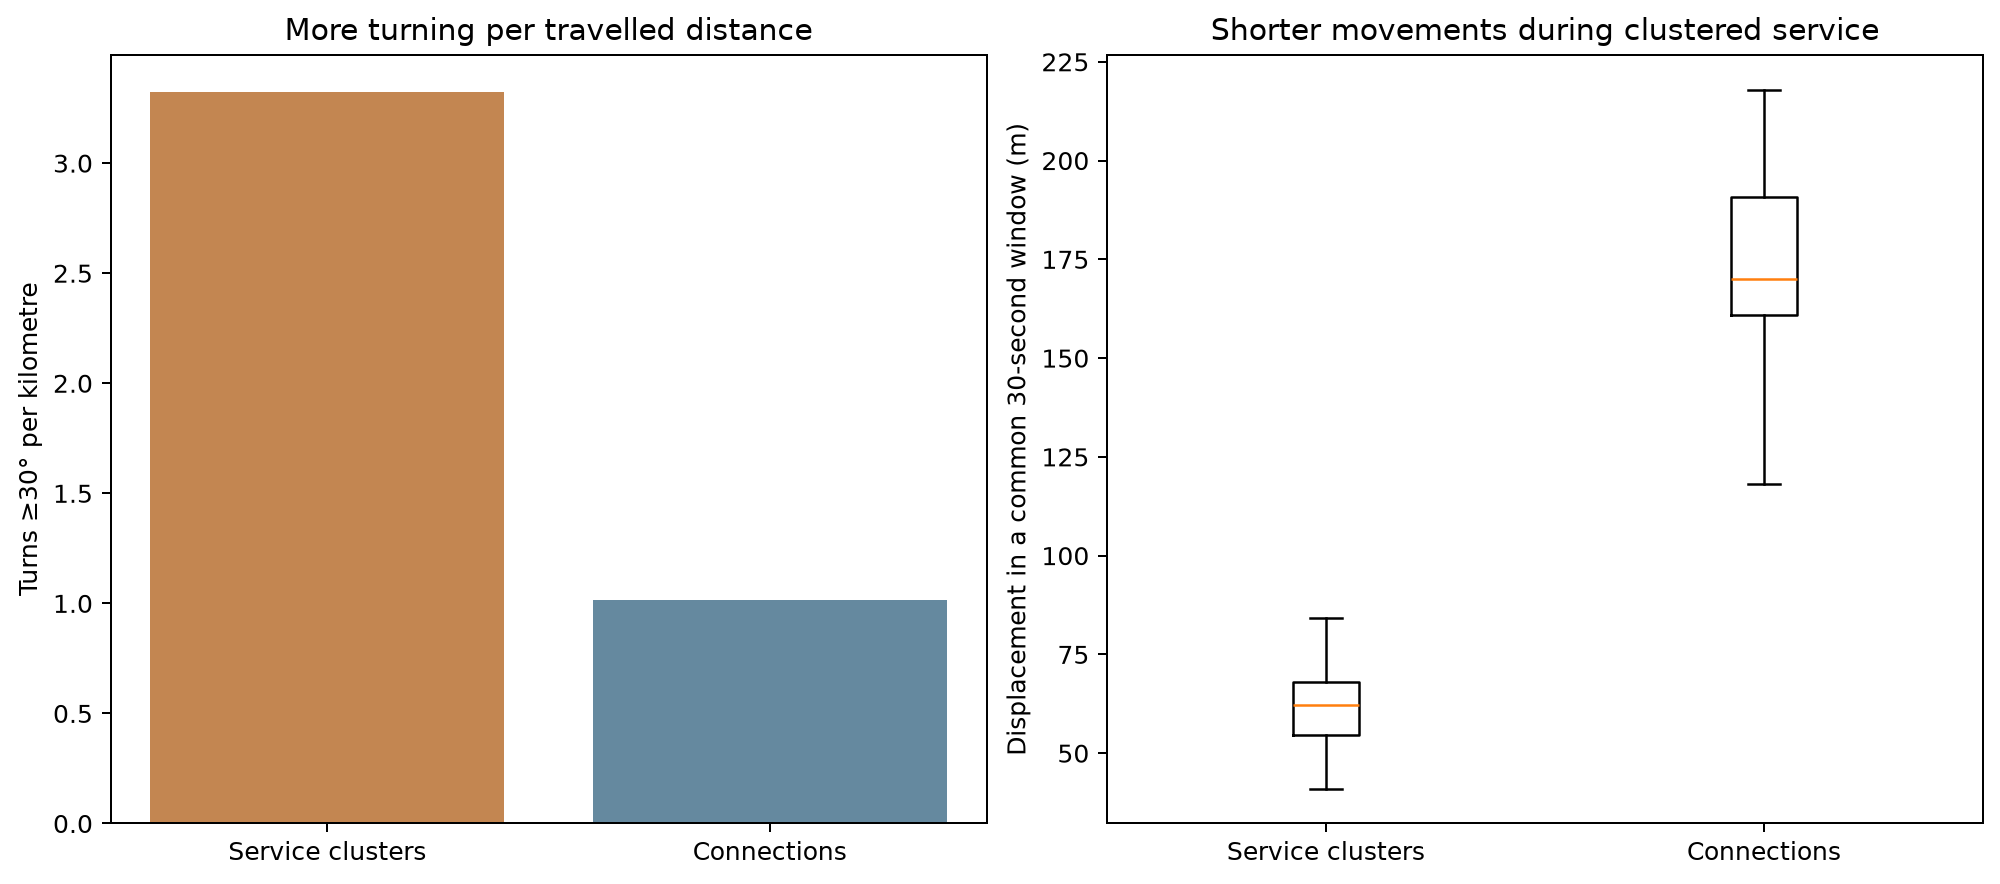

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def phase_movements(df, user_df):
    # Common 30-second windows prevent irregular raw GPS spacing from being
    # mistaken for a behavioural difference. These are analysis samples only.
    rows = []
    for name, q in user_df.groupby("route_section", sort=False):
        stamps = pd.to_datetime(q.gps_time, format="mixed").astype("int64").to_numpy()
        elapsed = (stamps - stamps[0]) / 1e9
        grid = np.arange(0, elapsed[-1], 30)
        if len(grid) < 3:
            continue
        xy = np.array(
            [
                np.interp(grid, elapsed, q.lng) * 95.2,
                np.interp(grid, elapsed, q.lat) * 111,
            ]
        ).T
        delta = np.diff(xy, axis=0)
        head = np.arctan2(delta[:, 0], delta[:, 1])
        turn = abs((np.diff(head) + np.pi) % (2 * np.pi) - np.pi) * 180 / np.pi
        phase = "Service clusters" if name.startswith("cluster") else "Connections"
        rows.extend(
            {"phase": phase, "distance_km": float(length), "turn_deg": float(angle)}
            for length, angle in zip(np.linalg.norm(delta, axis=1)[1:], turn)
        )
    d = pd.DataFrame(rows)
    groups = d.groupby("phase")
    rates = {
        name: float(q.turn_deg.ge(30).sum() / q.distance_km.sum()) for name, q in groups
    }
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
    labels = ["Service clusters", "Connections"]
    axes[0].bar(labels, [rates[x] for x in labels], color=["#c38651", "#65899f"])
    axes[0].set(
        ylabel="Turns ≥30° per kilometre", title="More turning per travelled distance"
    )
    axes[1].boxplot(
        [d[d.phase.eq(x)].distance_km * 1000 for x in labels], tick_labels=labels
    )
    axes[1].set(
        ylabel="Displacement in a common 30-second window (m)",
        title="Shorter movements during clustered service",
    )
    return {
        "comparison_interval_seconds": 30,
        "turns_ge30_per_km": rates,
        "median_30s_distance_km": groups.distance_km.median().to_dict(),
        "mean_30s_direction_change_deg": groups.turn_deg.mean().to_dict(),
    }


evidence = phase_movements(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/cluster_vs_connecting_movement.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_phase_movement_distributions",
  "insight_type": "exception_deviation",
  "insight": "Segments with frequent delivery completions contain more higher directional changes and short movements, while connecting segments between delivery clusters are more linear and longer.",
  "insight_value": {
    "comparison_interval_seconds": 30,
    "turns_ge30_per_km": {
      "Connections": 1.0148344129308948,
      "Service clusters": 3.324946456041474
    },
    "median_30s_distance_km": {
      "Connections": 0.17014119676076717,
      "Service clusters": 0.06223425269026005
    },
    "mean_30s_direction_change_deg": {
      "Connections": 14.195153633003764,
      "Service clusters": 20.908783598533365
    }
  },
  "plot": {
    "plot_type": "phase_distribution_comparison",
    "title": "Cluster and Connecting Movement",
    "file": "visualizations/cluster_vs_connecting_movement.png",
    "description": "Recomputed from the delivered CSVs; road geometry preserves mapped vertices. Movement comparisons use common 30-second analysis windows, not unequal raw GPS intervals."
  },
  "question": "How do movement direction and step length differ between delivery clusters and connecting segments?",
  "actionable_insight": "Compare direction-change and step-distance distributions rather than relying on a single route-average value.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef phase_movements(df,user_df):\n    # Common 30-second windows prevent irregular raw GPS spacing from being\n    # mistaken for a behavioural difference. These are analysis samples only.\n    rows=[]\n    for name,q in user_df.groupby('route_section',sort=False):\n        stamps=pd.to_datetime(q.gps_time,format='mixed').astype('int64').to_numpy()\n        elapsed=(stamps-stamps[0])/1e9;grid=np.arange(0,elapsed[-1],30)\n        if len(grid)<3:continue\n        xy=np.array([np.interp(grid,elapsed,q.lng)*95.2,np.interp(grid,elapsed,q.lat)*111]).T\n        delta=np.diff(xy,axis=0);head=np.arctan2(delta[:,0],delta[:,1]);turn=abs((np.diff(head)+np.pi)%(2*np.pi)-np.pi)*180/np.pi\n        phase='Service clusters' if name.startswith('cluster') else 'Connections'\n        rows.extend({'phase':phase,'distance_km':float(length),'turn_deg':float(angle)} for length,angle in zip(np.linalg.norm(delta,axis=1)[1:],turn))\n    d=pd.DataFrame(rows);groups=d.groupby('phase')\n    rates={name:float(q.turn_deg.ge(30).sum()/q.distance_km.sum()) for name,q in groups}\n    fig,axes=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)\n    labels=['Service clusters','Connections']\n    axes[0].bar(labels,[rates[x] for x in labels],color=['#c38651','#65899f'])\n    axes[0].set(ylabel='Turns ≥30° per kilometre',title='More turning per travelled distance')\n    axes[1].boxplot([d[d.phase.eq(x)].distance_km*1000 for x in labels],tick_labels=labels)\n    axes[1].set(ylabel='Displacement in a common 30-second window (m)',title='Shorter movements during clustered service')\n    return {'comparison_interval_seconds':30,'turns_ge30_per_km':rates,'median_30s_distance_km':groups.distance_km.median().to_dict(),\n            'mean_30s_direction_change_deg':groups.turn_deg.mean().to_dict()}\n\nevidence=phase_movements(df,user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "completion_time",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 12)

The route progresses mostly clockwise with very few immediate reversals. Within recurring cluster loops, farther tasks ahead are completed before a task just passed behind, and cluster service produces shorter, more directionally variable movements than the connecting legs.